# Filament segmentation - experiments

The pipeline lives in `src/filament.py`, so a fresh kernel is ready in seconds
rather than re-running twenty cells. Run section 1, then jump to whatever you need.

| | |
|---|---|
| `F.setup()` | data, splits, datasets - tile index cached, ~2 s warm |
| `F.load_model("best")` | the trained checkpoint |
| `F.evaluate(model, loader)` | tile-level pixel IoU and miss rate |
| `F.evaluate_pq(model, ctx)` | **Panoptic Quality - the competition metric** |
| `F.train(ctx, model, epochs=N, resume="last")` | continue training |

Current model: epoch 11 of the CLAHE + BCE/Tversky run, val IoU 0.4238,
19.3% complete misses (baseline: 0.39-0.48 IoU, 20-24% misses).

Editing `src/filament.py` needs no kernel restart - autoreload picks it up.
But changing the CLAHE settings or mask rasterisation invalidates the trained
checkpoints, which were trained on that exact preprocessing.

## 1. Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys

sys.path.insert(0, os.path.abspath("../src"))

import matplotlib.pyplot as plt
import numpy as np
import torch

import filament as F

ctx = F.setup()                 # cached tile index: seconds, not minutes
device = F.get_device()
print("device:", torch.cuda.get_device_name(0))

images 1154 ids / 707 files, annotations 8199
split: 993 train ids / 161 val ids
  train: 17442 tiles (cached)
  val: 4025 tiles (cached)
device: NVIDIA GeForce RTX 2050


## 2. Load the trained model

In [2]:
model, ck = F.load_model("best")        # or "last", or a full path

hist = json.load(open(os.path.join(F.CHECKPOINT_DIR, f"{F.TAG}_history.json"))) \
    if (json := __import__("json")) else None
print(f"{'ep':>3} {'IoU':>7} {'miss%':>7}")
for h in hist:
    star = "  <-- selected" if h["epoch"] == ck["epoch"] else ""
    print(f"{h['epoch']:3d} {h['val_iou']:7.4f} {100*h['miss_rate']:7.1f}{star}")

loaded unet_resnet34_clahe_bce_tversky_best.pt: epoch 11, best val IoU 0.4238
 ep     IoU   miss%
  2  0.3772    23.2
  3  0.3498    30.1
  4  0.3713    25.0
  5  0.3900    24.2
  6  0.3926    24.0
  7  0.3987    24.6
  8  0.4160    21.2
  9  0.2973    34.6
 10  0.3709    29.3
 11  0.4238    19.3  <-- selected
 12  0.4001    25.1
 13  0.4116    23.1
 14  0.2968    38.6
 15  0.3423    35.2


## 3. Tile-level evaluation

Pixel IoU over 512x512 tiles. This is the number training optimised, but it is
**not** what the competition scores - see section 5.

In [3]:
train_loader, val_loader = F.loaders(ctx, batch_size=4)

res = F.evaluate(model, val_loader)      # full val set, ~6 min
print(f"tiles with filaments : {res['n_tiles']}")
print(f"mean pixel IoU       : {res['mean_iou']:.4f}")
print(f"median IoU           : {res['median_iou']:.4f}")
print(f"complete misses      : {100*res['miss_rate']:.1f}%")
print(f"IoU > 0.5            : {100*res['iou_over_50']:.1f}%")

tiles with filaments : 1631
mean pixel IoU       : 0.4238
median IoU           : 0.4977
complete misses      : 19.3%
IoU > 0.5            : 49.5%


## 4. Full-image inference

The model sees 512x512 tiles, but filaments live on 2048x2048 frames and one
filament often crosses a tile boundary. `predict_full_image` runs the model over
a sliding window and **averages** the overlapping predictions - taking the max
instead would bias towards whichever tile happened to see the filament nearest
its centre.

image (2048, 2048), predicted 7 instances, ground truth 5


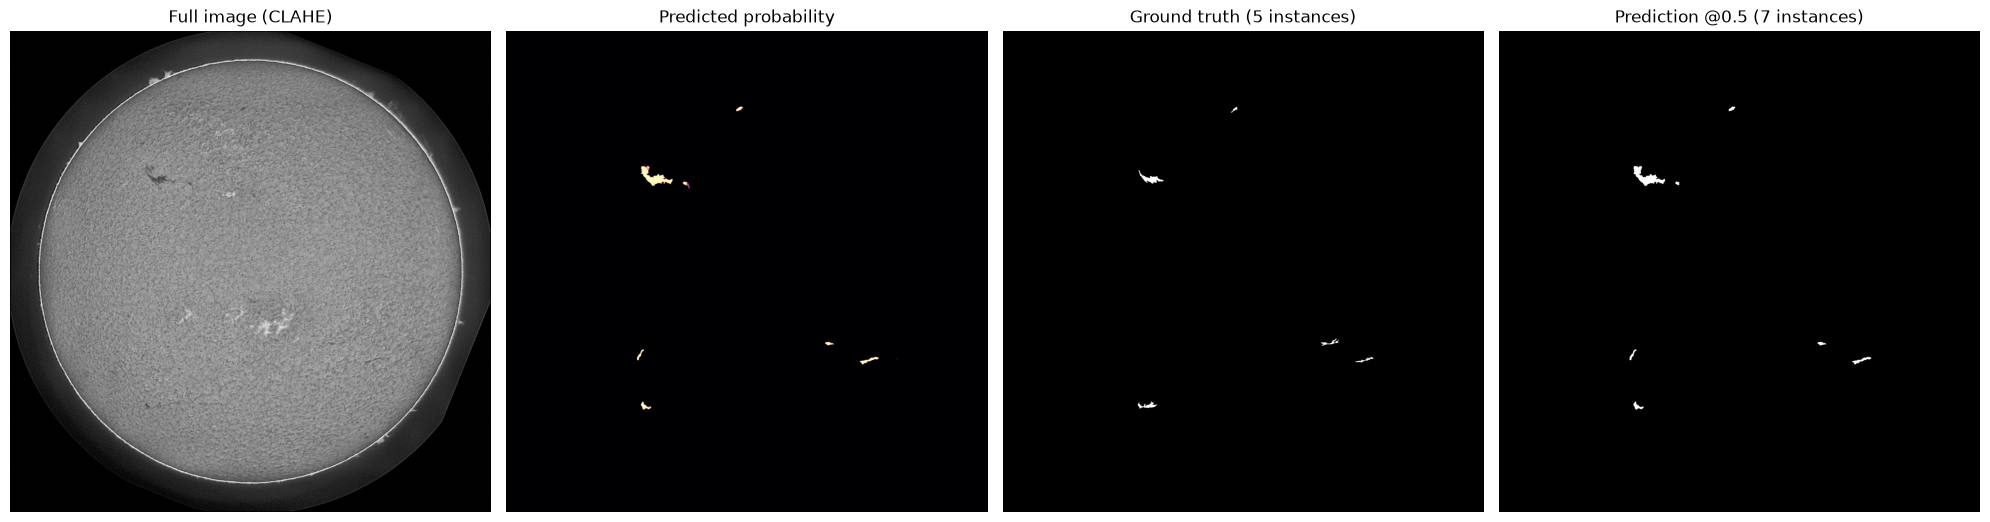

In [4]:
image_id = ctx.val_ids[0]
full = F.read_full_image(ctx.images_by_id, image_id)
prob = F.predict_full_image(model, full)

pred_inst, n_pred = F.label_instances(prob > 0.5)
gt_inst, n_gt = F.gt_instances(ctx.images_by_id, ctx.anns_by_image_id, image_id)
print(f"image {full.shape}, predicted {n_pred} instances, ground truth {n_gt}")

fig, axes = plt.subplots(1, 4, figsize=(20, 5.2))
axes[0].imshow(full, cmap='gray');                axes[0].set_title("Full image (CLAHE)")
axes[1].imshow(prob, cmap='magma', vmin=0, vmax=1); axes[1].set_title("Predicted probability")
axes[2].imshow(gt_inst > 0, cmap='gray');         axes[2].set_title(f"Ground truth ({n_gt} instances)")
axes[3].imshow(pred_inst > 0, cmap='gray');       axes[3].set_title(f"Prediction @0.5 ({n_pred} instances)")
for a in axes:
    a.axis('off')
plt.tight_layout()
plt.show()

## 5. Panoptic Quality - the competition metric

PQ scores **instances**, not pixels:

$$PQ = \underbrace{\frac{\sum_{(p,g) \in TP} IoU(p,g)}{|TP|}}_{\text{SQ, segmentation quality}}
      \times \underbrace{\frac{|TP|}{|TP| + \frac{1}{2}|FP| + \frac{1}{2}|FN|}}_{\text{RQ, recognition quality}}$$

A predicted instance matches a true one only when their IoU exceeds 0.5, which
makes the matching unique. The consequence that matters here: **one filament
predicted as two pieces scores zero**, even if nearly every pixel is right.
A worked example - a 100 px filament predicted as two 40 px halves - has pixel
IoU 0.80 but PQ 0.0, because neither piece reaches IoU 0.5 on its own, so it
counts as 2 false positives plus 1 false negative.

In [5]:
pq = F.evaluate_pq(model, ctx)          # all val images, ~2 min

print(f"\nimages evaluated : {pq['n_images']}")
print(f"PQ               : {pq['pq']:.4f}")
print(f"  SQ (quality)   : {pq['sq']:.4f}   mean IoU of matched instances")
print(f"  RQ (detection) : {pq['rq']:.4f}   F1-like detection rate")
print(f"TP {pq['tp']}   FP {pq['fp']}   FN {pq['fn']}")
print(f"\nfor contrast, tile-level pixel IoU was {res['mean_iou']:.4f}")

  0/161 images
  25/161 images
  50/161 images
  75/161 images
  100/161 images
  125/161 images
  150/161 images

images evaluated : 161
PQ               : 0.2520
  SQ (quality)   : 0.6409   mean IoU of matched instances
  RQ (detection) : 0.3933   F1-like detection rate
TP 597   FP 1328   FN 514

for contrast, tile-level pixel IoU was 0.4238


## 6. Where PQ is lost: fragmentation

If SQ is high but RQ is low, the masks are good but the model is not producing
one instance per filament. That is a post-processing problem, not a training
problem, and it is much cheaper to fix.

In [6]:
frag = F.fragmentation_stats(model, ctx, thr=0.5, min_area=20)
for k, v in frag.items():
    print(f"{k:26}: {v:.3f}" if isinstance(v, float) else f"{k:26}: {v}")

n_pred_instances          : 1925
n_gt_instances            : 1111
pred_per_gt_ratio         : 1.733
gt_found_by_0_pieces      : 0.122
gt_found_by_1_piece       : 0.726
gt_split_into_2plus       : 0.152
mean_pieces_per_found_gt  : 1.253


## 7. Tuning the operating point for PQ

Threshold and minimum instance area were never tuned - 0.5 and 20 px are just
defaults, and they were chosen for pixel IoU, not PQ. Raising `min_area` drops
specks that each cost a false positive; changing the threshold trades missed
filaments against spurious ones.

One pass computes every probability map, then scores all settings from it.

In [7]:
grid = F.evaluate_pq_grid(model, ctx,
                          thresholds=(0.3, 0.5, 0.7),
                          min_areas=(20, 100, 400))

print(f"\n{'thr':>5} {'min_area':>9} {'PQ':>8} {'SQ':>8} {'RQ':>8} "
      f"{'TP':>6} {'FP':>6} {'FN':>6}")
for r in grid:
    print(f"{r['threshold']:5.2f} {r['min_area']:9d} {r['pq']:8.4f} {r['sq']:8.4f} "
          f"{r['rq']:8.4f} {r['tp']:6d} {r['fp']:6d} {r['fn']:6d}")

best = grid[0]
print(f"\nbest: threshold {best['threshold']}, min_area {best['min_area']} "
      f"-> PQ {best['pq']:.4f}")
print(f"default (0.5 / 20) -> PQ "
      f"{[r for r in grid if r['threshold'] == 0.5 and r['min_area'] == 20][0]['pq']:.4f}")

  0/161 images
  25/161 images
  50/161 images
  75/161 images
  100/161 images
  125/161 images
  150/161 images

  thr  min_area       PQ       SQ       RQ     TP     FP     FN
 0.30       400   0.3066   0.6432   0.4766    617    861    494
 0.70       400   0.3005   0.6456   0.4655    577    791    534
 0.50       400   0.2955   0.6423   0.4601    577    820    534
 0.30       100   0.2777   0.6414   0.4330    632   1176    479
 0.70       100   0.2756   0.6432   0.4284    606   1112    505
 0.50       100   0.2699   0.6409   0.4212    597   1127    514
 0.30        20   0.2585   0.6414   0.4031    632   1393    479
 0.70        20   0.2571   0.6432   0.3997    606   1315    505
 0.50        20   0.2520   0.6409   0.3933    597   1328    514

best: threshold 0.3, min_area 400 -> PQ 0.3066
default (0.5 / 20) -> PQ 0.2520


## 7b. Cutting false positives

The tuning above treats every blob alike. Before adding filters, measure which
properties of a predicted blob actually separate real filaments from false
positives.

The maps are cached to disk (`F.cache_val_probs`), so everything from here on
runs on the CPU in seconds per setting - and can run while the GPU is busy
training. The cache key comes from the checkpoint, so loading a different model
cannot silently reuse stale maps.

In [ ]:
PROB_NAME = f"{ck['epoch']}_{ck['best_val_iou']:.4f}"     # identifies this checkpoint
F.cache_val_probs(model, ctx, PROB_NAME)                   # ~90 s the first time
probs = F.load_val_probs(ctx, PROB_NAME)

# ground truth rasterised once, as int16 (instance ids are small)
gt_cache = {i: F.gt_instances(ctx.images_by_id, ctx.anns_by_image_id, i, F.GT_MIN_AREA)[0]
                 .astype(np.int16) for i in ctx.val_ids}

d = F.component_diagnostics(ctx, probs, low=0.3, min_area=20, gt_cache=gt_cache)
tp = d["tp"].astype(bool)
print(f"{len(tp)} predicted blobs at threshold 0.3: {tp.sum()} match a real filament "
      f"({100 * tp.mean():.0f}%), {(~tp).sum()} do not\n")


def table(name, x, edges):
    print(name)
    print(f"  {'bin':>17} {'blobs':>6} {'real':>7}   share of all false positives")
    n_fp = (~tp).sum()
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (x >= lo) & (x < hi)
        if m.sum():
            print(f"  {lo:8.3g}-{hi:<8.3g} {m.sum():6d} {100 * tp[m].mean():6.1f}%   "
                  f"{100 * (~tp[m]).sum() / n_fp:5.1f}%")
    print()


table("peak probability inside the blob", d["max_p"], [0, .5, .9, .97, .99, 1.01])
table("area (px)", d["area"], [20, 100, 400, 800, 1600, 3200, 1e9])
table("elongation (major / minor axis)", d["elong"], [0, 1.5, 2, 3, 5, 1e9])

**What the table shows** (checkpoint at the time of writing): blobs whose peak
probability never reaches about 0.99 are almost never real, yet make up roughly
44% of all false positives; blobs under 400 px are the same. Shape (elongation)
separates far less than confidence does - so confidence gating, not shape
filtering, is the lever worth pulling.

That maps onto **hysteresis thresholding**: keep a blob's full extent at a low
threshold (`low`), but only if some pixel inside it reaches a high one (`high`).
The tuning below uses a split of validation *by photo*: settings are chosen on
half A and scored once on half B, which was never used for tuning. Tuning and
scoring on the same 161 images flatters the result.

In [ ]:
A, B = F.split_val_by_file(ctx)
print(f"tune on A: {len(A)} images    held out B: {len(B)} images\n")

configs = {
    "default            (0.5 / no gate / 20 px)":  dict(low=0.5, min_area=20),
    "tuned min-area     (0.3 / no gate / 800 px)": dict(low=0.3, min_area=800),
    "hysteresis         (0.4 / 0.995 / 400 px)":   dict(low=0.4, high=0.995, min_area=400),
}

print(f"{'':44} {'tune A':>8} {'HELD-OUT B':>11} {'all val':>8}")
pp = {}
for name, cfg in configs.items():
    a = F.pq_from_probs(A, probs, ctx, gt_cache, **cfg)
    b = F.pq_from_probs(B, probs, ctx, gt_cache, **cfg)
    v = F.pq_from_probs(ctx.val_ids, probs, ctx, gt_cache, **cfg)
    pp[name] = (a, b, v)
    print(f"{name:44} {a['pq']:8.4f} {b['pq']:11.4f} {v['pq']:8.4f}")

b = pp["hysteresis         (0.4 / 0.995 / 400 px)"][1]
print(f"\nheld-out B with hysteresis: TP {b['tp']}  FP {b['fp']}  FN {b['fn']}  "
      f"(SQ {b['sq']:.3f}, RQ {b['rq']:.3f})")

**Read the held-out column, not the tuning column.** The gain of hysteresis over
the plain min-area filter was about +0.04 on the half it was tuned on and only
about +0.01 on the held-out half; the rest was tuning optimism. Against the
original default the held-out gain stays large.

Things tried that did **not** help, so they are not in the setting: closing
(radius 2-10 px) to rejoin fragments, an elongation floor, and a mean-confidence
floor. All were within noise of no filter, and larger closing radii steadily
hurt - they glue separate filaments together. Fragmentation is real but is not
where PQ is being lost; false detections are.

## 8. Training curves

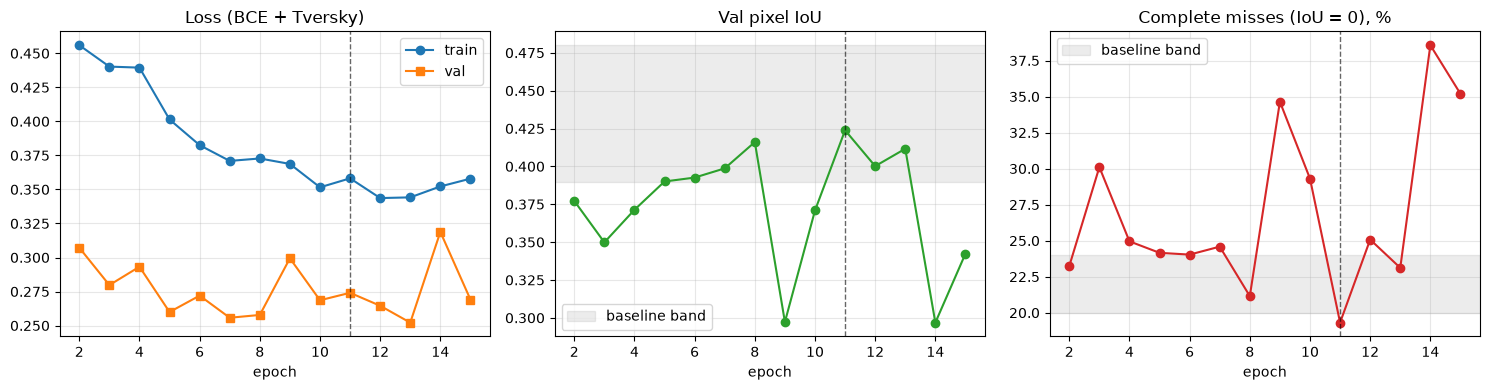

In [8]:
ep = [h["epoch"] for h in hist]
best_ep = ck["epoch"]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ep, [h["train_loss"] for h in hist], "o-", label="train")
ax[0].plot(ep, [h["val_loss"] for h in hist], "s-", label="val")
ax[0].set_title("Loss (BCE + Tversky)"); ax[0].legend()
ax[1].plot(ep, [h["val_iou"] for h in hist], "o-", color="tab:green")
ax[1].axhspan(0.39, 0.48, alpha=.15, color="grey", label="baseline band")
ax[1].set_title("Val pixel IoU"); ax[1].legend()
ax[2].plot(ep, [100 * h["miss_rate"] for h in hist], "o-", color="tab:red")
ax[2].axhspan(20, 24, alpha=.15, color="grey", label="baseline band")
ax[2].set_title("Complete misses (IoU = 0), %"); ax[2].legend()
for a in ax:
    a.axvline(best_ep, color="k", ls="--", lw=1, alpha=.6)
    a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 9. Continue training with a decaying learning rate

The run so far never converged: IoU swung between 0.297 and 0.424 with no
damping at a constant 1e-4.

**First attempt, and why it did nothing.** A 10-epoch cosine schedule was run
from the best checkpoint, but it was built on an optimizer created in the
notebook, while `F.train` steps its *own* optimizer. The scheduler decayed an
optimizer that never trained anything, so the learning rate stayed at 1.0e-4 in
every epoch (confirmed from the `lr` column of the history file). That run was
therefore just ten more epochs at a constant rate:

| | IoU, epochs 12-21 |
|---|---|
| mean | 0.4196 |
| std | 0.0240 |
| best single epoch | 0.4515 |
| last 3 epochs | 0.4309, 0.4100, 0.3870 |

Its "best" checkpoint is the luckiest of ten noisy epochs, so the headline IoU
of 0.4515 overstates the model. Its mean (0.42) is no better than before.

**The fix.** `F.train` now takes `scheduler_fn`, a callable that receives the
optimizer it creates, and rejects a ready-made scheduler object with an error
explaining why. `new_run=True` loads weights and optimizer state but resets the
epoch counter and best-IoU tracker, so a new recipe under a new tag can actually
save a best checkpoint; and the logged `lr` is now the rate the epoch trained at.

The cell below is guarded: a full run is 10 epochs at roughly 22-33 minutes each.

In [ ]:
RUN_TRAINING = False          # set True to launch (about 4-5 hours)

EPOCHS = 10
if RUN_TRAINING:
    model = F.build_model(device)
    model, history = F.train(
        ctx, model, epochs=EPOCHS, lr=1e-4,
        resume="best", new_run=True,                 # weights + optimizer, fresh counters
        tag=F.TAG + "_cosine",                       # new tag: existing checkpoints untouched
        scheduler_fn=F.cosine_schedule(EPOCHS),      # 1e-4 decaying to ~3e-6
    )

## 10. Where this stands

Run the cells above for the current numbers. What they showed on the epoch-11
checkpoint:

* **Tile pixel IoU 0.4238, 19.3% complete misses** - at or better than the
  Dice+BCE baseline (0.39-0.48, 20-24%).
* **PQ is far lower than pixel IoU suggests.** Instance-level scoring punishes
  the fragmentation that pixel IoU forgives, and that gap is the single biggest
  thing between this model and a competitive submission.

Priorities, cheapest first:

1. **Post-processing for fragmentation** - morphological closing, or joining
   pieces that lie along a shared spine, before labelling instances. No
   retraining, and section 6 measures whether it worked.
2. **Tune the operating point** (section 7) - also free.
3. **A learning-rate schedule** - the run never converged, so there is probably
   headroom left in the weights.
4. **Predicting instances directly** rather than a binary mask plus connected
   components - the annotations carry spines and chirality that a binary model
   throws away.

Not done yet: **test-set inference and a submission file.** `Documentation/`
and `submissions/` are empty, so the required format is unknown - that needs the
competition spec before it can be written. `Data/.../test/test_images` holds 180
images, and `F.predict_full_image` already produces masks for them.